In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

$$\ln p_{\theta }(x)=\ln \int p_{\theta }(x|z)p(z)dz $$
$$ {\int p_{\theta }(x|z)p(z)dz=\mathbb {E} _{z\sim q_{\phi }(\cdot |x)}\left[{\frac {p_{\theta }(x,z)}{q_{\phi }(z|x)}}\right]} $$
$$ {\ln p_{\theta }(x)=\ln \mathbb {E} _{z\sim q_{\phi }(\cdot |x)}\left[{\frac {p_{\theta }(x,z)}{q_{\phi }(z|x)}}\right]\geq \mathbb {E} _{z\sim q_{\phi }(\cdot |x)}\left[\ln {\frac {p_{\theta }(x,z)}{q_{\phi }(z|x)}}\right]} $$
$$ {\ln p_{\theta }(x)-\mathbb {E} _{z\sim q_{\phi }(\cdot |x)}\left[\ln {\frac {p_{\theta }(x,z)}{q_{\phi }(z|x)}}\right]=D_{\mathit {KL}}(q_{\phi }(\cdot |x)\|p_{\theta }(\cdot |x))\geq 0} $$
$$ {\displaystyle L(\phi ,\theta ;x):=\ln p_{\theta }(x)-D_{\mathit {KL}}(q_{\phi }(\cdot |x)\|p_{\theta }(\cdot |x))} $$

Because we cannot mathematically calculate the true probability distribution of our data, we use ELBO to estimate the lower bound, which we can then optimize

$$minGmaxDV(D,G)=Ex∼p(x)[logD(x)]+Ez∼p(z)[log(1−D(G(z)))]$$

Discriminator Loss $$−(E[logD(x)]+E[log(1−D(G(z)))])$$

Generator Loss $$−E[logD(G(z))]$$

## VAE

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super(VAE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 28 * 28),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, 28 * 28))
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

In [ ]:
def elbo_loss_function(recon_x, x, mu, logvar):
    BCE = nn.functional.binary_cross_entropy(recon_x, x.view(-1, 28 * 28), reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return BCE + KLD

In [ ]:
class MNISTCSVDataset(Dataset):
    def __init__(self, csv_file):
        df = pd.read_csv(csv_file)

        self.labels = df['label'].values
        pixel_df = df.drop(columns=['label'])

        self.pixels = pixel_df.values.astype(np.float32) / 255.0

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = torch.tensor(self.pixels[idx]).view(1, 28, 28)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, label

In [ ]:
def plot_latten_distribution(model, test_loader, device):
    model.eval()
    all_mu, all_labels = [], []

    with torch.no_grad():
        for data, labels in test_loader:
            data = data.to(device)
            mu, _ = model.encode(data.view(-1, 28 * 28))
            all_mu.append(mu.cpu().numpy())
            all_labels.append(labels.numpy())

    all_mu = np.concatenate(all_mu, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)

    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(all_mu[:, 0], all_mu[:, 1], c=all_labels, cmap='tab10', alpha=0.6, s=2)
    plt.colorbar(scatter, label='Class')
    plt.title('MNIST Distribution')
    plt.xlabel('z1')
    plt.ylabel('z2')
    plt.grid(True, alpha=0.2)
    plt.show()

In [ ]:
def digits_reconstructed(model, device):
    model.eval()
    n = 15
    digit_size = 28
    figure = np.zeros((digit_size * n, digit_size * n))

    grid_x = np.linspace(-3, 3, n)
    grid_y = np.linspace(-3, 3, n)

    with torch.no_grad():
        for i, yi in enumerate(grid_y):
            for j, xi in enumerate(grid_x):
                z_sample = torch.tensor([[xi, yi]], dtype=torch.float32).to(device)
                x_decoded = model.decode(z_sample)
                digit = x_decoded[0].reshape(digit_size, digit_size).cpu().numpy()

                figure[(n - 1 - i) * digit_size: (n - i) * digit_size,
                       j * digit_size: (j + 1) * digit_size] = digit

    plt.figure(figsize=(10, 10))
    plt.imshow(figure, cmap='Greys_r')
    plt.title('15x15 mesh')
    plt.axis('off')
    plt.show()

In [ ]:
def train(epochs=15, batch_size=128, latent_dim=2, train_csv_path=None,
          test_csv_path=None, lr=1e-3):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    train_dataset = MNISTCSVDataset(csv_file=train_csv_path)
    test_dataset = MNISTCSVDataset(csv_file=test_csv_path)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model = VAE(latent_dim=latent_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model.train()
    for epoch in range(1, epochs + 1):
        train_loss = 0
        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(device)
            optimizer.zero_grad()

            recon_batch, mu, logvar = model(data)
            loss = elbo_loss_function(recon_batch, data, mu, logvar)

            loss.backward()
            train_loss += loss.item()
            optimizer.step()

        print(f"Epoch {epoch:02d}/{epochs} | Avg ELBO Loss: {train_loss / len(train_loader.dataset):.4f}")

    plot_latten_distribution(model, test_loader, device)

    digits_reconstructed(model, device)

Epoch 01/15 | Avg ELBO Loss: 188.4827
Epoch 02/15 | Avg ELBO Loss: 160.5741
Epoch 03/15 | Avg ELBO Loss: 154.3191
Epoch 04/15 | Avg ELBO Loss: 150.3755
Epoch 05/15 | Avg ELBO Loss: 147.7914
Epoch 06/15 | Avg ELBO Loss: 146.1993
Epoch 07/15 | Avg ELBO Loss: 144.9109
Epoch 08/15 | Avg ELBO Loss: 144.0646
Epoch 09/15 | Avg ELBO Loss: 143.3048
Epoch 10/15 | Avg ELBO Loss: 142.7692
Epoch 11/15 | Avg ELBO Loss: 142.0471
Epoch 12/15 | Avg ELBO Loss: 141.4908
Epoch 13/15 | Avg ELBO Loss: 141.1623
Epoch 14/15 | Avg ELBO Loss: 140.6908
Epoch 15/15 | Avg ELBO Loss: 140.3326


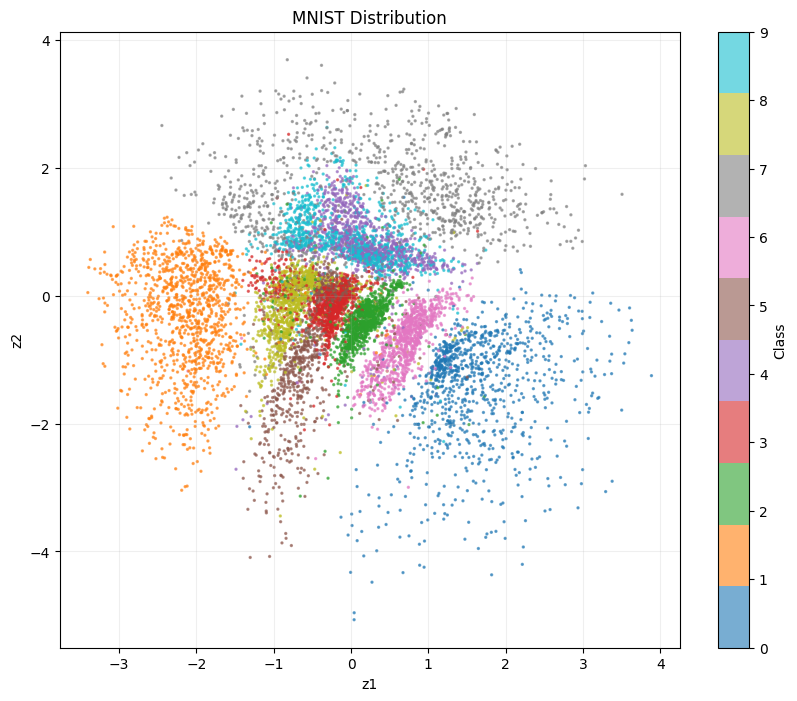

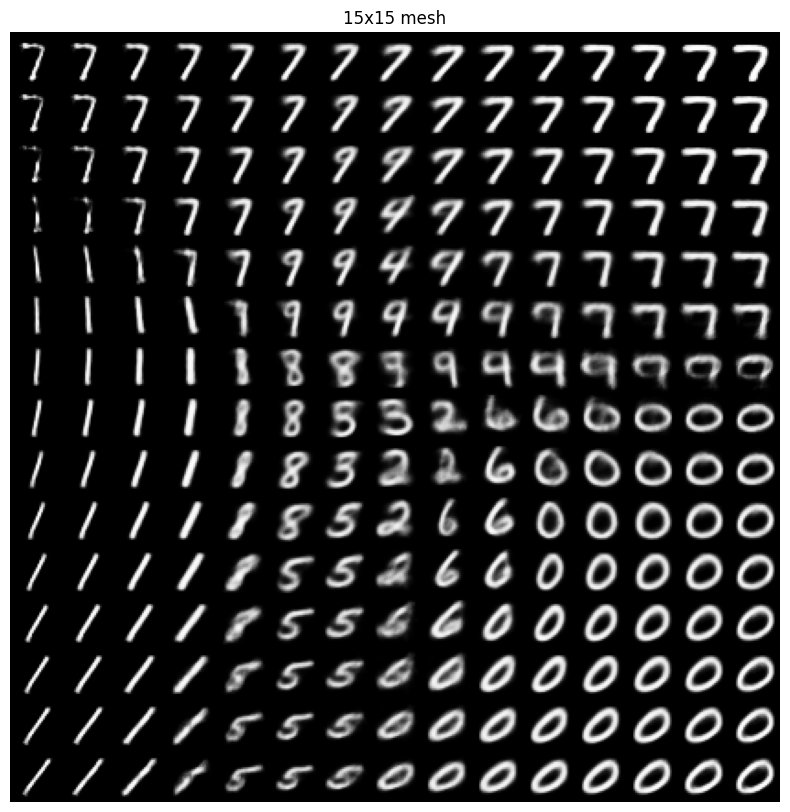

In [ ]:
train(train_csv_path="data/mnist_train.csv",
      test_csv_path="data/mnist_test.csv")

## Supervised VAE

In [ ]:
class SupervisedVAE(VAE):
    def __init__(self, latent_dim=1, num_classes=10):
        super().__init__(latent_dim)
        self.num_classes = num_classes

        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim + num_classes, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 28 * 28),
            nn.Sigmoid()
        )

    def decode(self, z, labels_onehot):
        decoder_input = torch.cat([z, labels_onehot], dim=1)
        return self.decoder(decoder_input)

    def forward(self, x, labels_onehot):
        mu, logvar = self.encode(x.view(-1, 28 * 28))
        z = self.reparameterize(mu, logvar)
        return self.decode(z, labels_onehot), mu, logvar

In [ ]:
def plot_generated_digit_grid(model, device):
    model.eval()

    num_latent_points = 15
    num_classes = 10
    digit_size = 28
    figure = np.zeros((digit_size * num_latent_points, digit_size * num_classes))

    latent_mesh = np.linspace(-2.5, 2.5, num_latent_points)

    with torch.no_grad():
        for i, z_val in enumerate(latent_mesh):
            for label in range(num_classes):
                z_tensor = torch.tensor([[z_val]], dtype=torch.float32).to(device)

                label_tensor = torch.tensor([label], dtype=torch.long)
                lbl_onehot = nn.functional.one_hot(label_tensor, num_classes=10).float().to(device)

                x_decoded = model.decode(z_tensor, lbl_onehot)
                digit = x_decoded.reshape(digit_size, digit_size).cpu().numpy()

                figure[i * digit_size: (i + 1) * digit_size,
                       label * digit_size: (label + 1) * digit_size] = digit

    plt.figure(figsize=(12, 15))
    plt.imshow(figure, cmap='Greys_r')

    plt.xticks(np.arange(digit_size / 2, digit_size * num_classes, digit_size), labels=range(10))
    plt.yticks(np.arange(digit_size / 2, digit_size * num_latent_points, digit_size), labels=np.round(latent_mesh, 2))
    plt.xlabel('label index', fontsize=12)
    plt.ylabel('z', fontsize=12)
    plt.title('15x10 digits mesh', fontsize=14)
    plt.show()

In [ ]:
def train_supervised(epochs=15, batch_size=128, latent_dim=1, train_csv_path=None, lr=1e-3):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    train_dataset = MNISTCSVDataset(csv_file=train_csv_path)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    model = SupervisedVAE(latent_dim=1, num_classes=10).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model.train()
    for epoch in range(1, epochs + 1):
        train_loss = 0
        for batch_idx, (data, labels) in enumerate(train_loader):
            data = data.to(device)

            labels_onehot = nn.functional.one_hot(labels, num_classes=10).float().to(device)

            optimizer.zero_grad()
            recon_batch, mu, logvar = model(data, labels_onehot)
            loss = elbo_loss_function(recon_batch, data, mu, logvar)

            loss.backward()
            train_loss += loss.item()
            optimizer.step()

        print(f"Epoch {epoch:02d}/{epochs} | Avg ELBO Loss: {train_loss / len(train_loader.dataset):.4f}")

    plot_generated_digit_grid(model, device)

Epoch 01/15 | Avg ELBO Loss: 174.0834
Epoch 02/15 | Avg ELBO Loss: 152.6547
Epoch 03/15 | Avg ELBO Loss: 149.2539
Epoch 04/15 | Avg ELBO Loss: 147.5646
Epoch 05/15 | Avg ELBO Loss: 146.3913
Epoch 06/15 | Avg ELBO Loss: 145.3485
Epoch 07/15 | Avg ELBO Loss: 144.9169
Epoch 08/15 | Avg ELBO Loss: 144.2648
Epoch 09/15 | Avg ELBO Loss: 143.8591
Epoch 10/15 | Avg ELBO Loss: 143.3490
Epoch 11/15 | Avg ELBO Loss: 142.9700
Epoch 12/15 | Avg ELBO Loss: 142.5677
Epoch 13/15 | Avg ELBO Loss: 142.3793
Epoch 14/15 | Avg ELBO Loss: 142.1096
Epoch 15/15 | Avg ELBO Loss: 141.8992


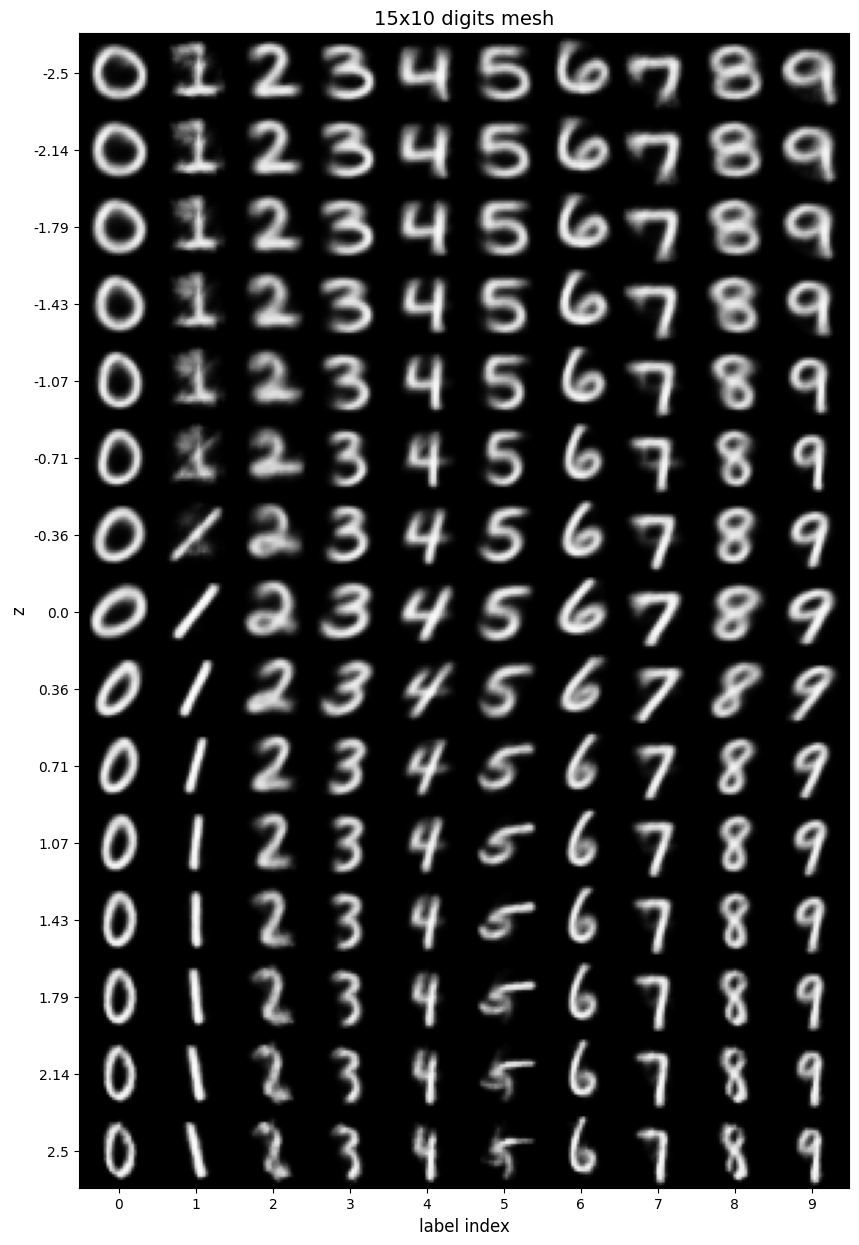

In [ ]:
train_supervised(train_csv_path="data/mnist_train.csv")

## GAN

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=2):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(256),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(512),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(1024),
            nn.Linear(1024, 28 * 28),
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z).view(-1, 1, 28, 28)

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, img):
        flat_img = img.view(img.size(0), -1)
        return self.model(flat_img)

In [ ]:
def plot_loss(d_losses, g_losses):
    plt.figure(figsize=(10, 5))
    plt.plot(d_losses, label="Discriminator Loss", color="royalblue", lw=2)
    plt.plot(g_losses, label="Generator Loss", color="crimson", lw=2)
    plt.xlabel("Epoch")
    plt.ylabel("BCE Loss")
    plt.title("GAN Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

In [ ]:
def generate_gan_grid(generator, device, latent_dim=2, n=15):
    generator.eval()

    digit_size = 28
    figure = np.zeros((digit_size * n, digit_size * n))

    grid_x = np.linspace(-2.0, 2.0, n)
    grid_y = np.linspace(-2.0, 2.0, n)

    with torch.no_grad():
        for i, yi in enumerate(grid_y):
            for j, xi in enumerate(grid_x):
                z_sample = torch.tensor([[xi, yi]], dtype=torch.float32).to(device)

                fake_image = generator(z_sample)

                digit = fake_image.view(digit_size, digit_size).cpu().numpy()
                digit = (digit + 1.0) / 2.0

                figure[(n - 1 - i) * digit_size: (n - i) * digit_size,
                       j * digit_size: (j + 1) * digit_size] = digit

    plt.figure(figsize=(10, 10))
    plt.imshow(figure, cmap='gray')

    plt.xticks(np.arange(digit_size / 2, digit_size * n, digit_size), labels=np.round(grid_x, 2))
    plt.yticks(np.arange(digit_size / 2, digit_size * n, digit_size), labels=np.round(grid_y[::-1], 2))

    plt.xlabel('z1', fontsize=11)
    plt.ylabel('z2', fontsize=11)
    plt.title(f'{n}x{n} GAN mesh', fontsize=13)

    plt.show()


In [ ]:
def train_gan(epochs=15, batch_size=128, latent_dim=2, train_csv_path=None, lr=1e-3):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    dataset = MNISTCSVDataset(csv_file=train_csv_path)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    netG = Generator(latent_dim=latent_dim).to(device)
    netD = Discriminator().to(device)

    criterion = nn.BCELoss()
    optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(0.5, 0.999))
    optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(0.5, 0.999))

    d_losses = []
    g_losses = []

    for epoch in range(1, epochs + 1):
        epoch_d_loss = 0
        epoch_g_loss = 0

        for batch_idx, (real_images, _) in enumerate(dataloader):
            current_batch_size = real_images.size(0)
            real_images = real_images.to(device)

            real_labels = torch.ones(current_batch_size, 1).to(device)
            fake_labels = torch.zeros(current_batch_size, 1).to(device)

            optimizerD.zero_grad()

            output_real = netD(real_images)
            lossD_real = criterion(output_real, real_labels)

            z = torch.randn(current_batch_size, latent_dim).to(device)
            fake_images = netG(z)
            output_fake = netD(fake_images.detach())
            lossD_fake = criterion(output_fake, fake_labels)

            lossD = lossD_real + lossD_fake
            lossD.backward()
            optimizerD.step()
            epoch_d_loss += lossD.item()

            optimizerG.zero_grad()

            output_fake_for_G = netD(fake_images)
            lossG = criterion(output_fake_for_G, real_labels)

            lossG.backward()
            optimizerG.step()
            epoch_g_loss += lossG.item()

        avg_d_loss = epoch_d_loss / len(dataloader)
        avg_g_loss = epoch_g_loss / len(dataloader)
        d_losses.append(avg_d_loss)
        g_losses.append(avg_g_loss)

        print(f"Epoch [{epoch:02d}/{epochs}] | D Loss: {avg_d_loss:.4f} | G Loss: {avg_g_loss:.4f}")

    plot_loss(d_losses, g_losses)

    generate_gan_grid(netG, device)

Epoch [01/45] | D Loss: 1.0844 | G Loss: 4.2395
Epoch [02/45] | D Loss: 1.0503 | G Loss: 3.4360
Epoch [03/45] | D Loss: 0.4975 | G Loss: 11.5773
Epoch [04/45] | D Loss: 0.3356 | G Loss: 15.2213
Epoch [05/45] | D Loss: 0.3217 | G Loss: 17.0133
Epoch [06/45] | D Loss: 0.3190 | G Loss: 14.5431
Epoch [07/45] | D Loss: 0.2249 | G Loss: 15.4763
Epoch [08/45] | D Loss: 0.2526 | G Loss: 15.7252
Epoch [09/45] | D Loss: 0.2584 | G Loss: 13.7685
Epoch [10/45] | D Loss: 0.2101 | G Loss: 12.6374
Epoch [11/45] | D Loss: 0.1712 | G Loss: 13.2053
Epoch [12/45] | D Loss: 0.1525 | G Loss: 13.6462
Epoch [13/45] | D Loss: 0.1559 | G Loss: 14.0160
Epoch [14/45] | D Loss: 0.1519 | G Loss: 13.1540
Epoch [15/45] | D Loss: 0.1858 | G Loss: 12.2791
Epoch [16/45] | D Loss: 0.1415 | G Loss: 12.7348
Epoch [17/45] | D Loss: 0.1560 | G Loss: 12.8427
Epoch [18/45] | D Loss: 0.1632 | G Loss: 11.7995
Epoch [19/45] | D Loss: 0.1525 | G Loss: 11.8577
Epoch [20/45] | D Loss: 0.1611 | G Loss: 11.2147
Epoch [21/45] | D Loss

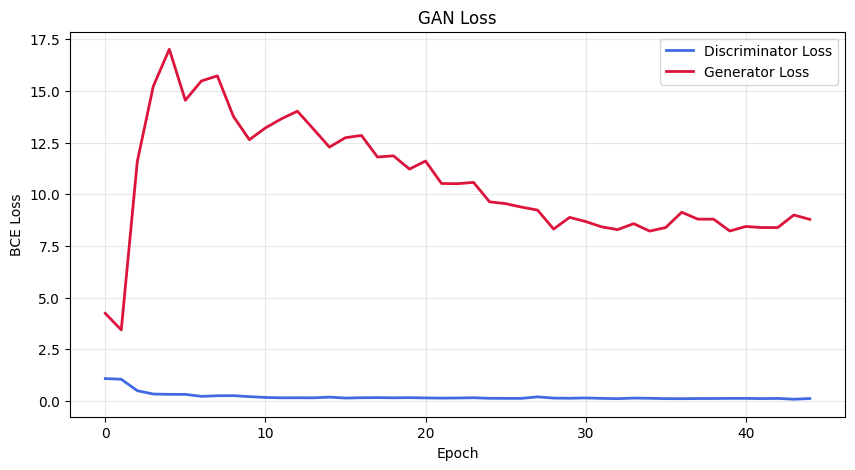

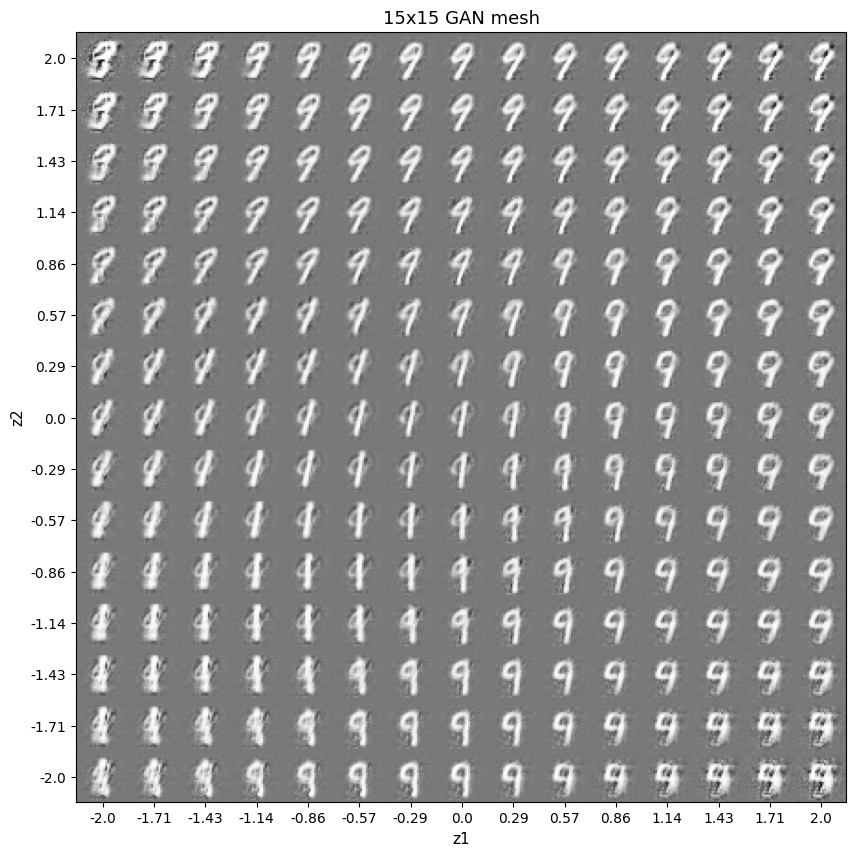

In [ ]:
train_gan(epochs=45, train_csv_path="data/mnist_train.csv")

## Gradient Reversal

Gradient reversal is a layer which helps us combine the losses of generator and discriminator into one, which is helpful during the optimisation part, because you only need to optimize one loss

In [ ]:
class GradientReversalFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = alpha
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.alpha, None

class GradientReversal(nn.Module):
    def __init__(self, alpha=1.0):
        super(GradientReversal, self).__init__()
        self.alpha = alpha

    def forward(self, x):
        return GradientReversalFunction.apply(x, self.alpha)

In [ ]:
class UnifiedGAN(nn.Module):
    def __init__(self, latent_dim=2, alpha=1.0):
        super(UnifiedGAN, self).__init__()
        self.generator = Generator(latent_dim)
        self.discriminator = Discriminator()
        self.grl = GradientReversal(alpha)

    def forward(self, real_images, z):
        fake_images = self.generator(z)

        out_real = self.discriminator(real_images)

        grl_fake_images = self.grl(fake_images)
        out_fake = self.discriminator(grl_fake_images)

        return out_real, out_fake

In [ ]:
def train_uni_gan(epochs=15, batch_size=128, latent_dim=2, train_csv_path=None, lr=3e-4):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    dataset = MNISTCSVDataset(csv_file=train_csv_path)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    gan_system = UnifiedGAN(latent_dim=latent_dim, alpha=1).to(device)

    optimizer = optim.Adam(gan_system.parameters(), lr=lr, betas=(0.5, 0.999))
    criterion = nn.BCELoss()
    losses = []

    for epoch in range(1, epochs + 1):
        epoch_loss = 0
        for batch_idx, (real_images, _) in enumerate(dataloader):
            current_batch_size = real_images.size(0)
            real_images = real_images.to(device)

            real_labels = torch.ones(current_batch_size, 1).to(device)
            fake_labels = torch.zeros(current_batch_size, 1).to(device)

            z = torch.randn(current_batch_size, latent_dim).to(device)

            optimizer.zero_grad()

            out_real, out_fake = gan_system(real_images, z)

            loss_real = criterion(out_real, real_labels)
            loss_fake = criterion(out_fake, fake_labels)
            total_loss = loss_real + loss_fake

            total_loss.backward()
            optimizer.step()

            epoch_loss += total_loss.item()

        losses.append(epoch_loss / len(dataloader))
        print(f"Epoch [{epoch:02d}/{epochs}] | Combined System Loss: {epoch_loss / len(dataloader):.4f}")

    plt.figure(figsize=(10, 5))
    plt.plot(losses, label="Loss", color="royalblue", lw=2)
    plt.xlabel("Epoch")
    plt.ylabel("BCE Loss")
    plt.title("GAN Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    generate_gan_grid(gan_system.generator, device)

Epoch [01/45] | Combined System Loss: 0.7167
Epoch [02/45] | Combined System Loss: 0.6909
Epoch [03/45] | Combined System Loss: 1.3275
Epoch [04/45] | Combined System Loss: 1.3348
Epoch [05/45] | Combined System Loss: 1.2998
Epoch [06/45] | Combined System Loss: 1.1573
Epoch [07/45] | Combined System Loss: 1.0459
Epoch [08/45] | Combined System Loss: 0.9213
Epoch [09/45] | Combined System Loss: 0.8750
Epoch [10/45] | Combined System Loss: 0.7968
Epoch [11/45] | Combined System Loss: 0.6913
Epoch [12/45] | Combined System Loss: 0.5584
Epoch [13/45] | Combined System Loss: 0.5554
Epoch [14/45] | Combined System Loss: 0.5148
Epoch [15/45] | Combined System Loss: 0.4406
Epoch [16/45] | Combined System Loss: 0.4221
Epoch [17/45] | Combined System Loss: 0.3991
Epoch [18/45] | Combined System Loss: 0.3523
Epoch [19/45] | Combined System Loss: 0.3434
Epoch [20/45] | Combined System Loss: 0.3153
Epoch [21/45] | Combined System Loss: 0.2619
Epoch [22/45] | Combined System Loss: 0.2507
Epoch [23/

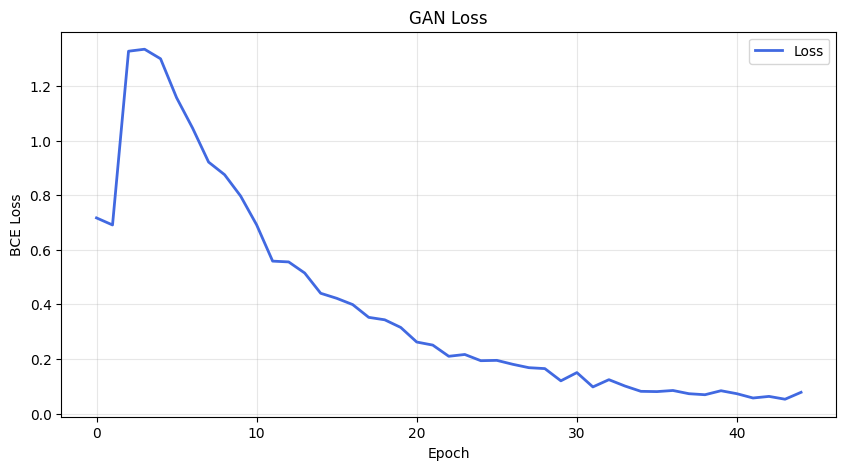

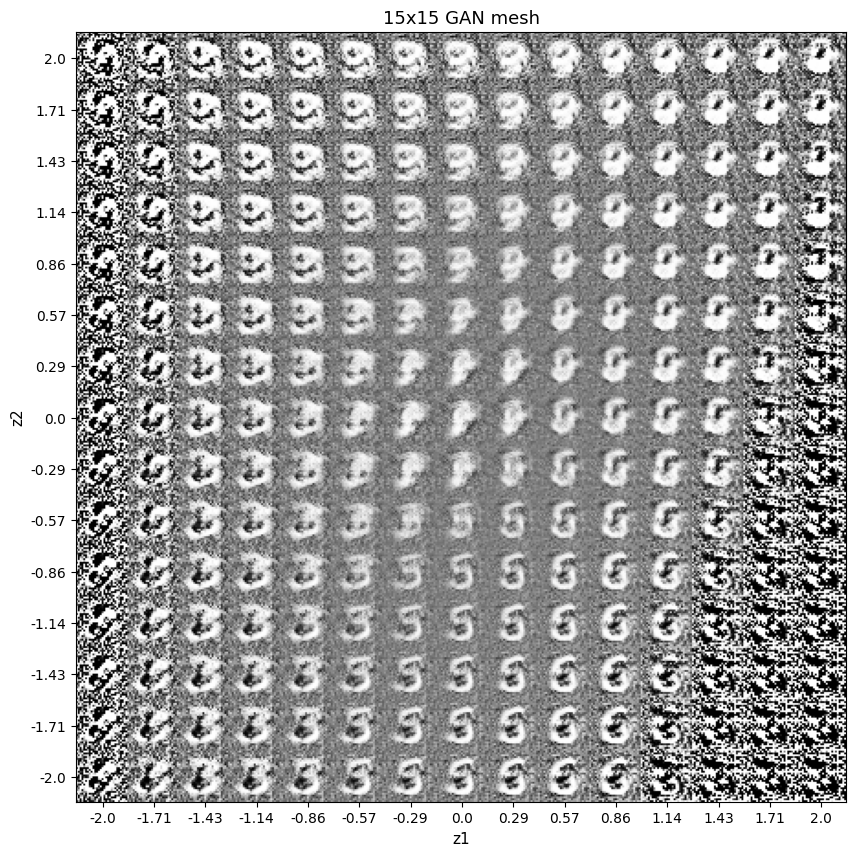

In [ ]:
train_uni_gan(epochs=45, train_csv_path="data/mnist_train.csv")

## Supervised GAN

To make the gan supervised, i'm going to add one-hot encodings of number labels to the latent vector for both generator and discriminator

In [ ]:
class ConditionalGenerator(nn.Module):
    def __init__(self, latent_dim=2, num_classes=10):
        super(ConditionalGenerator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim + num_classes, 256),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(256),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(512),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(1024),
            nn.Linear(1024, 28 * 28),
            nn.Tanh()
        )

    def forward(self, z, labels_onehot):
        gen_input = torch.cat([z, labels_onehot], dim=1)
        return self.model(gen_input).view(-1, 1, 28, 28)

In [ ]:
class ConditionalDiscriminator(nn.Module):
    def __init__(self, num_classes=10):
        super(ConditionalDiscriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(28 * 28 + num_classes, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, img, labels_onehot):
        flat_img = img.view(img.size(0), -1)
        disc_input = torch.cat([flat_img, labels_onehot], dim=1)
        return self.model(disc_input)

In [ ]:
class UnifiedConditionalGAN(nn.Module):
    def __init__(self, latent_dim=2, num_classes=10, alpha=1.0):
        super(UnifiedConditionalGAN, self).__init__()
        self.generator = ConditionalGenerator(latent_dim, num_classes)
        self.discriminator = ConditionalDiscriminator(num_classes)
        self.grl = GradientReversal(alpha)

    def forward(self, real_images, z, labels_onehot):
        fake_images = self.generator(z, labels_onehot)

        out_real = self.discriminator(real_images, labels_onehot)

        grl_fake_images = self.grl(fake_images)
        out_fake = self.discriminator(grl_fake_images, labels_onehot)

        return out_real, out_fake

In [ ]:
def visualize_constant_noise_digits(generator, device, latent_dim=2, num_classes=10):
    generator.eval()

    digit_size = 28

    frozen_z = torch.randn(1, latent_dim).to(device)
    batch_z = frozen_z.repeat(num_classes, 1)

    target_labels = torch.arange(0, num_classes, dtype=torch.long).to(device)
    labels_onehot = nn.functional.one_hot(target_labels, num_classes=num_classes).float()

    with torch.no_grad():
        generated_images = generator(batch_z, labels_onehot).cpu().numpy()

    fig, axes = plt.subplots(1, num_classes, figsize=(15, 2.5))

    for label in range(num_classes):
        img = generated_images[label, 0]
        img = (img + 1.0) / 2.0

        axes[label].imshow(img, cmap='gray')
        axes[label].set_title(f"Label: {label}", fontsize=10)
        axes[label].axis('off')

    plt.suptitle("Class mesh", fontsize=13, y=1.05)
    plt.show()

In [ ]:
def train_sup_uni_gan(epochs=15, batch_size=128, latent_dim=2, num_classes=10, alpha=1.0, train_csv_path=None, lr=5e-5):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    dataset = MNISTCSVDataset(csv_file=train_csv_path)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    gan_system = UnifiedConditionalGAN(latent_dim=latent_dim, alpha=alpha).to(device)

    optimizer = optim.Adam(gan_system.parameters(), lr=lr, betas=(0.5, 0.999))
    criterion = nn.BCELoss()
    losses = []

    for epoch in range(1, epochs + 1):
        epoch_loss = 0
        for batch_idx, (real_images, labels) in enumerate(dataloader):
            current_batch_size = real_images.size(0)
            real_images = real_images.to(device)

            real_labels = torch.ones(current_batch_size, 1).to(device)
            fake_labels = torch.zeros(current_batch_size, 1).to(device)
            labels_onehot = nn.functional.one_hot(labels, num_classes=num_classes).float().to(device)

            z = torch.randn(current_batch_size, latent_dim).to(device)

            optimizer.zero_grad()

            out_real, out_fake = gan_system(real_images, z, labels_onehot)

            loss_real = criterion(out_real, real_labels)
            loss_fake = criterion(out_fake, fake_labels)
            total_loss = loss_real + loss_fake

            total_loss.backward()
            optimizer.step()

            epoch_loss += total_loss.item()

        losses.append(epoch_loss / len(dataloader))
        print(f"Epoch [{epoch:02d}/{epochs}] | Combined System Loss: {epoch_loss / len(dataloader):.4f}")

    plt.figure(figsize=(10, 5))
    plt.plot(losses, label="Loss", color="royalblue", lw=2)
    plt.xlabel("Epoch")
    plt.ylabel("BCE Loss")
    plt.title("GAN Loss")
    plt.grid(True, alpha=0.3)
    plt.show()

    visualize_constant_noise_digits(gan_system.generator, device)

Epoch [01/50] | Combined System Loss: 1.2978
Epoch [02/50] | Combined System Loss: 1.3409
Epoch [03/50] | Combined System Loss: 1.3519
Epoch [04/50] | Combined System Loss: 1.3631
Epoch [05/50] | Combined System Loss: 1.3701
Epoch [06/50] | Combined System Loss: 1.3837
Epoch [07/50] | Combined System Loss: 1.3873
Epoch [08/50] | Combined System Loss: 1.3873
Epoch [09/50] | Combined System Loss: 1.3869
Epoch [10/50] | Combined System Loss: 1.3866
Epoch [11/50] | Combined System Loss: 1.3871
Epoch [12/50] | Combined System Loss: 1.3866
Epoch [13/50] | Combined System Loss: 1.3868
Epoch [14/50] | Combined System Loss: 1.3867
Epoch [15/50] | Combined System Loss: 1.3865
Epoch [16/50] | Combined System Loss: 1.3862
Epoch [17/50] | Combined System Loss: 1.3862
Epoch [18/50] | Combined System Loss: 1.3858
Epoch [19/50] | Combined System Loss: 1.3853
Epoch [20/50] | Combined System Loss: 1.2973
Epoch [21/50] | Combined System Loss: 1.2281
Epoch [22/50] | Combined System Loss: 1.1827
Epoch [23/

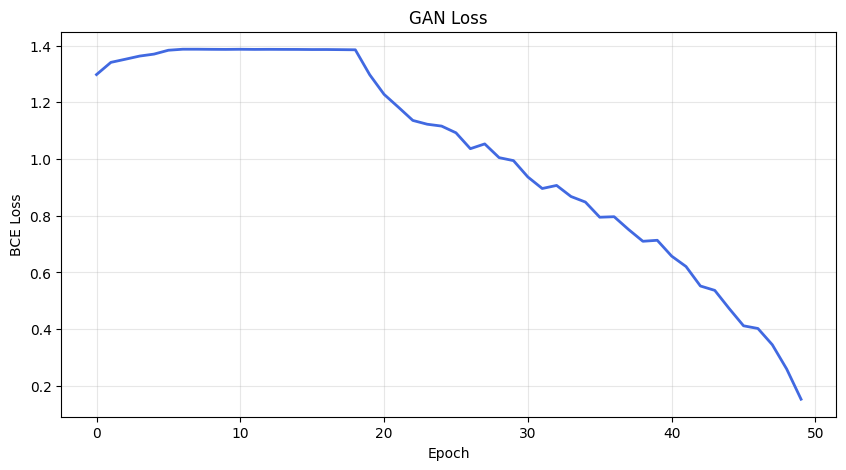

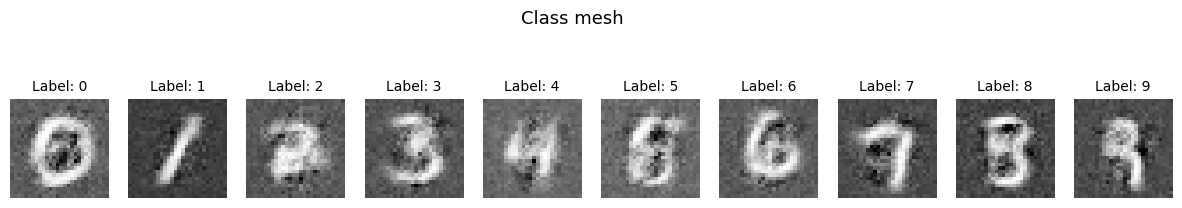

In [ ]:
train_sup_uni_gan(epochs=50, train_csv_path="data/mnist_train.csv")

Epoch [01/50] | Combined System Loss: 1.2945
Epoch [02/50] | Combined System Loss: 1.3375
Epoch [03/50] | Combined System Loss: 1.3527
Epoch [04/50] | Combined System Loss: 1.3613
Epoch [05/50] | Combined System Loss: 1.3757
Epoch [06/50] | Combined System Loss: 1.3876
Epoch [07/50] | Combined System Loss: 1.3858
Epoch [08/50] | Combined System Loss: 1.3857
Epoch [09/50] | Combined System Loss: 1.3875
Epoch [10/50] | Combined System Loss: 1.3876
Epoch [11/50] | Combined System Loss: 1.3870
Epoch [12/50] | Combined System Loss: 1.3866
Epoch [13/50] | Combined System Loss: 1.3863
Epoch [14/50] | Combined System Loss: 1.3859
Epoch [15/50] | Combined System Loss: 1.3853
Epoch [16/50] | Combined System Loss: 1.3440
Epoch [17/50] | Combined System Loss: 1.2402
Epoch [18/50] | Combined System Loss: 1.1930
Epoch [19/50] | Combined System Loss: 1.1382
Epoch [20/50] | Combined System Loss: 1.1024
Epoch [21/50] | Combined System Loss: 1.0790
Epoch [22/50] | Combined System Loss: 1.0636
Epoch [23/

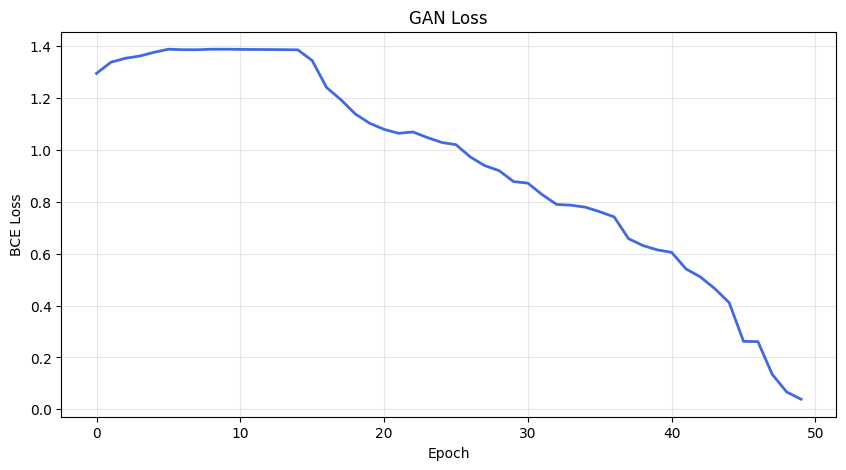

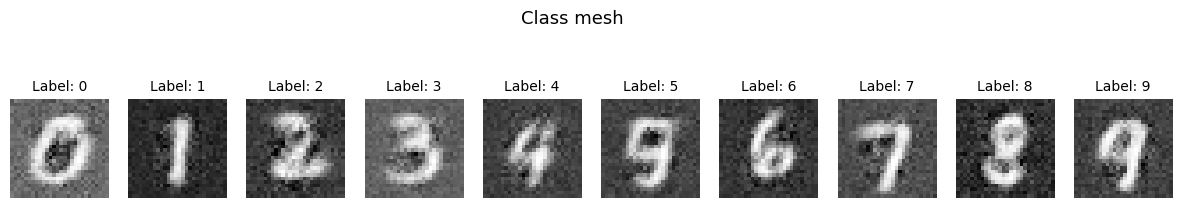

In [ ]:
train_sup_uni_gan(epochs=50, train_csv_path="data/mnist_train.csv", alpha=2)

Epoch [01/60] | Combined System Loss: 1.2923
Epoch [02/60] | Combined System Loss: 1.3375
Epoch [03/60] | Combined System Loss: 1.3516
Epoch [04/60] | Combined System Loss: 1.3604
Epoch [05/60] | Combined System Loss: 1.3711
Epoch [06/60] | Combined System Loss: 1.3866
Epoch [07/60] | Combined System Loss: 1.3862
Epoch [08/60] | Combined System Loss: 1.3869
Epoch [09/60] | Combined System Loss: 1.3863
Epoch [10/60] | Combined System Loss: 1.3860
Epoch [11/60] | Combined System Loss: 1.3853
Epoch [12/60] | Combined System Loss: 1.3340
Epoch [13/60] | Combined System Loss: 1.2339
Epoch [14/60] | Combined System Loss: 1.2024
Epoch [15/60] | Combined System Loss: 1.1749
Epoch [16/60] | Combined System Loss: 1.1483
Epoch [17/60] | Combined System Loss: 1.1046
Epoch [18/60] | Combined System Loss: 1.0873
Epoch [19/60] | Combined System Loss: 1.0569
Epoch [20/60] | Combined System Loss: 1.0437
Epoch [21/60] | Combined System Loss: 0.9917
Epoch [22/60] | Combined System Loss: 0.9931
Epoch [23/

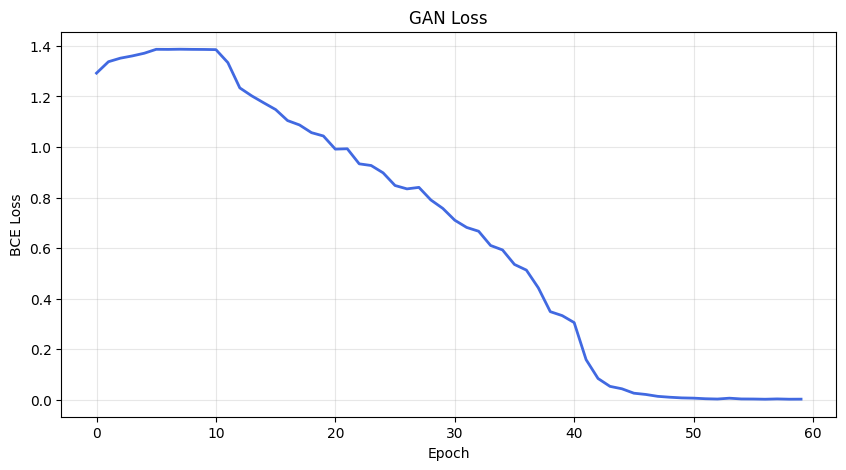

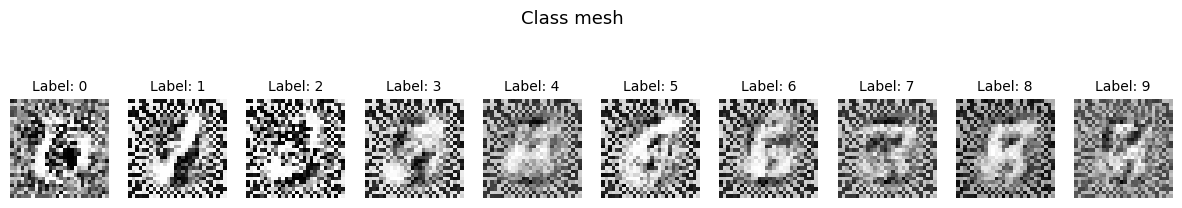

In [ ]:
train_sup_uni_gan(epochs=60, train_csv_path="data/mnist_train.csv", alpha=0.5)